<a href="https://colab.research.google.com/github/micjung15-cmd/-/blob/main/%EC%82%AC%EC%9D%B4%EB%93%9C_%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B8(2026_10_11).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
#csv 파일 불러오기
!git clone 'https://github.com/micjung15-cmd/-.git'
%cd -

Cloning into '-'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (67/67), done.
remote: Total 72 (delta 20), reused 18 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 27.61 MiB | 8.88 MiB/s, done.
Resolving deltas: 100% (20/20), done.


UsageError: %cd -: No previous directory to change to.


In [10]:
import os
os.chdir('-')

#파일 목록 확인
!ls

app.py	notebooks		       PROJECT_PLAN.md	 sql
data	olist_order_items_dataset.csv  README.md
docs	portfolio		       requirements.txt


# 1. 데이터 품질 진단

목적: 분석을 시작하기 전에 "이 데이터로 무엇을 말할 수 있고 무엇을 말할 수 없는가" 를 먼저 확정합니다.

여기서 나온 숫자는 그대로 docs/FINDINGS.md 의 "데이터 범위"와 대시보드 '데이터 신뢰도' 탭에 들어갑니다.

In [ ]:
#환경 세팅①
import duckdb, pandas as pd
import matplotlib, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)

In [ ]:
#환경 세팅② - 한글 깨짐 방지

for _f in [
    "AppleGothic",
    "Malgun Gothic",
    "NanumGothic",
    "NanumBarunGothic",
    "Noto Sans CJK KR",
    "Noto Sans KR",
]:
  if _f in {f.name for f in matplotlib.font_manager.fontManager.ttflist}:
    plt.rcParams["font.family"] = _f
    break

plt.rcParams["axes.unicode_minus"] = False

In [ ]:
#환경세팅③  DuckDB는 CSV를 그대로 읽습니다. 적재 과정이 따로 없습니다.

con = duckdb.connect()
con.execute(open("sql/base.sql", encoding="utf-8").read().format(data="data/raw"))

#sql 사용
def q(sql):
  """SQL을 실행해 pandas DataFrame으로 돌려줍니다."""
  return con.sql(sql).df()

#주문 건수 확인
q("SELECT count(*) AS 주문수 FROM order_fact")

,주문수
0,99441


(1)눈으로 보기

sql/base.sql 이 만들어 둔 order_fact 는 1행 = 주문 1건 입니다.

앞으로 모든 분석은 이 뷰 하나만 봅니다.

In [ ]:
q("DESCRIBE order_fact")

,column_name,column_type,null,key,default,extra
0,order_id,VARCHAR,YES,None,None,None
1,customer_unique_id,VARCHAR,YES,None,None,None
2,customer_state,VARCHAR,YES,None,None,None
3,order_status,VARCHAR,YES,None,None,None
4,purchased_at,TIMESTAMP,YES,None,None,None
5,purchase_month,DATE,YES,None,None,None
6,delivered_at,TIMESTAMP,YES,None,None,None
7,delay_days,BIGINT,YES,None,None,None
8,is_late,BOOLEAN,YES,None,None,None
9,delay_bucket,VARCHAR,YES,None,None,None


In [ ]:
q("SELECT * FROM order_fact LIMIT 5")

,order_id,customer_unique_id,customer_state,order_status,purchased_at,purchase_month,delivered_at,delay_days,is_late,delay_bucket,item_count,gmv,freight,seller_id,seller_state,category,review_score,has_review
0,f8868b8046c99c3b68a17b935efe47a9,8032878a9fcb1e269a19befcc57ec8c3,MG,delivered,2018-06-21 02:36:49,2018-06-01,2018-06-29 19:06:54,-20,False,①[1분위] 17일 조기,1,109.99,89.44,3b872fd4747f01cc56206f2934198618,SP,bed_bath_table,3,True
1,8c46c4b2bbf318ff31368bc87309662e,9f62f7e0d0cbeab75bfbd518bf2d6566,PA,delivered,2017-02-05 22:32:10,2017-02-01,2017-02-16 14:22:49,-27,False,①[1분위] 17일 조기,1,159.00,47.61,80e6699fe29150b372a0c8a1ebf7dcc8,PR,sports_leisure,5,True
2,ddd1cd1f0c2ecee8f709cd6c8d22daab,0ef6c429cb296ab0f6aec6baedf64774,RJ,delivered,2018-07-24 11:07:22,2018-07-01,2018-07-31 18:36:27,-14,False,②[2분위] 12일 조기,1,80.00,19.75,3d49bfdd1b43a7fe169b3740067acc61,MG,construction_tools_construction,5,True
3,c6c26ee904fd7f85a965423bec883fe6,ed20342b0e962655501a9a62f29e9a3c,SP,invoiced,2017-09-15 14:28:21,2017-09-01,NaT,<NA>,<NA>,미상,1,89.90,9.44,d7b2377bae6ace1b11fc69a11900ac36,SP,fashion_underwear_beach,2,True
4,488bbe7460a648792b11ac9b3755e44f,a72a2d4e19868dba726c0e6f49198c7e,GO,delivered,2017-11-14 15:44:11,2017-11-01,2017-11-29 21:29:04,-9,False,③[3분위] 7일 조기,1,248.99,74.69,7ddcbb64b5bc1ef36ca8c151f6ec77df,SP,luggage_accessories,1,True


(2)이 데이터로 답할 수 있는 범위

전체 주문 중 실제로 분석에 쓸 수 있는 건 몇 건인지 셉니다.

COUNT(*) FILTER (WHERE 조건) 은 조건을 만족하는 행만 세는 문법입니다.

확인할 것 — '분석 가능' 건수가 전체의 몇 %인가요? 이 비율이 낮다면 앞으로의 결론은 전체 주문 이 아니라 그 부분집합 에 대한 이야기입니다.그 사실을 결론에 반드시 함께 써야 합니다.

In [ ]:
q("""
SELECT '전체 주문' AS 항목, count(*) AS 건수
FROM order_fact
UNION ALL
SELECT '배송 완료',   count(*) FILTER (WHERE order_status = 'delivered')
FROM order_fact
UNION ALL
SELECT '수령일 있음',  count(*) FILTER (WHERE delivered_at IS NOT NULL)
FROM order_fact
UNION ALL
SELECT '리뷰 있음',   count(*) FILTER (WHERE has_review)
FROM order_fact
UNION ALL
SELECT '분석 가능 (지연일+리뷰)', count(*) FILTER (WHERE delay_days IS NOT NULL AND has_review)
FROM order_fact
ORDER BY 건수 DESC
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,항목,건수
0,전체 주문,99441
1,리뷰 있음,98673
2,배송 완료,96478
3,수령일 있음,96476
4,분석 가능 (지연일+리뷰),95830


(3)결합 단계마다 표본이 얼마나 줄어드나

테이블을 붙일 때마다 몇 건이 사라지는지 추적합니다.

크게 줄어드는 단계가 곧 결론의 한계입니다.

JOIN (= INNER JOIN) 은 양쪽에 다 있는 행만 남기고, LEFT JOIN 은 왼쪽을 전부 남깁니다.아래는 일부러 JOIN 을 써서 손실을 드러냅니다.

In [ ]:
q("""
SELECT '① 원본 주문' AS 단계, count(*) AS 건수
FROM orders
UNION ALL
SELECT '② + 상품 결합', count(*)
FROM orders
JOIN order_items USING (order_id)
UNION ALL
SELECT '③ + 리뷰 결합', count(*)
FROM orders
JOIN order_items USING (order_id)
JOIN reviews USING (order_id)
UNION ALL
SELECT '④ + 수령일 존재', count(*)
FROM order_fact
WHERE delay_days IS NOT NULL AND has_review
""")

,단계,건수
0,① 원본 주문,99441
1,② + 상품 결합,98666
2,③ + 리뷰 결합,97917
3,④ + 수령일 존재,95830


(4)중복 리뷰한 주문에 리뷰가 여러 건 달린 경우가 있습니다.

점수가 서로 다르다면, 어느 것을 남길지가 결과를 바꾸는 결정 이 됩니다.

sql/base.sql 은 "가장 나중에 쓴 1건"을 남기도록 해 두었습니다.

그 선택이 타당한지 여기서 확인하세요.

In [ ]:
q("""
SELECT count(*) AS 중복_주문수, count(*) FILTER (WHERE mx <> mn) AS 점수가_다른_주문수, round(avg(mx - mn), 2) AS 평균_점수차
FROM (SELECT order_id, max(CAST(review_score AS INT)) AS mx, min(CAST(review_score AS INT)) AS mn
FROM reviews_raw
WHERE review_score IS NOT NULL
GROUP BY order_id
HAVING count(*) > 1
)""")

,중복_주문수,점수가_다른_주문수,평균_점수차
0,547,202,0.75


**(5)【직접 작성】 재구매 고객은 몇 명인가**

함정이 하나 있습니다.
- customer_id — 주문할 때마다 새로 발급되는 값. 사람이 아닙니다.
- customer_unique_id — 실제 사람.
customer_id 로 세면 재구매율이 0%로 나옵니다.
실무에서 실제로 자주 나는 사고입니다.

**할 일: 아래 두 숫자를 각각 구하고, 차이가 왜 나는지 docs/FINDINGS.md 에 적으세요**.
1. customer_id 기준 "2회 이상 주문한 고객" 비율
2. customer_unique_id 기준 "2회 이상 주문한 고객" 비율

힌트```
sql
WITH per_person AS ( SELECT <기준컬럼>, count() AS n
FROM order_fact
GROUP BY 1
)
SELECT count() AS 고객수, count() FILTER (WHERE n >= 2) AS 재구매고객수, round(100.0 * count() FILTER (WHERE n >= 2) / count(*), 2) AS 재구매율
FROM per_person````

order_fact에는customer_unique_id만 있습니다.

customer_id기준은 orders` 뷰를 쓰세요.

In [ ]:
#customer_id 기준 "2회 이상 주문한 고객" 비율

q("""
WITH per_person AS (
  SELECT customer_id, count(*) AS n
  FROM orders
  GROUP BY 1
  )
  SELECT
  count(*) AS 고객수,
  count(*) FILTER (WHERE n>=2) AS 재구매고객수,
  round(100.0*count(*)FILTER(WHERE n>=2)/count(*), 2) AS 재구매율
  FROM per_person
""")

,고객수,재구매고객수,재구매율
0,99441,0,0.0


In [ ]:
#customer_unique_id 기준 "2회 이상 주문한 고객" 비율

q("""
WITH per_person AS (
  SELECT customer_unique_id, count(*) AS n
  FROM order_fact
  GROUP BY 1
  )
SELECT
count(*) AS 고객수,
COUNT(*) FILTER (WHERE n>=2) AS 재구매고객수,
ROUND(100*count(*)FILTER(WHERE n>=2)/count(*), 2) AS 재구매율
FROM per_person

""")

,고객수,재구매고객수,재구매율
0,96096,2997,3.12


정리

아래 빈칸을 채워 docs/FINDINGS.md 의 "데이터 범위"로 옮기세요.

- 전체 주문 [ ] 건 중 분석 가능 [ ] 건 ([ ]%)
- 빠진 이유: 리뷰 없음 [ ] 건 / 수령일 결측 [ ] 건 / 취소·미배송 [ ] 건
- 중복 리뷰 [ ] 건, 그중 점수가 다른 것 [ ] 건 → 최신 1건 채택- 재구매 고객 [ ] 명 ([ ]%) → 04 노트북에서 이 숫자가 결정적입니다
- 따라서 이 분석의 결론은 [ 어떤 부분집합 ] 에 대한 이야기입니다

# 2. 지연과 리뷰

핵심 질문> **배송이 늦으면 리뷰 점수가 실제로 떨어지는가. 며칠부터 급락하는가.**답이 나오면 그대로 운영 기준이 됩니다. "지연 N일을 넘기지 않는다"가 물류 SLA가 되니까요.

In [21]:
#환경 세팅①
import duckdb, pandas as pd
import matplotlib, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)

In [22]:
#환경 세팅② 한글 깨짐 방지
for _f in [
    "AppleGothic",
    "Malgun Gothic",
    "NanumGothic",
    "NanumBarunGothic",
    "Noto Sans CJK KR",
    "Noto Sans KR",
]:
  if _f in {f.name for f in matplotlib.font_manager.fontManager.ttflist}:
    plt.rcParams["font.family"] = _f
    break

plt.rcParams["axes.unicode_minus"] = False

In [23]:
#환경 세팅③

con = duckdb.connect()
con.execute(open("sql/base.sql", encoding="utf-8").read().format(data="data/raw"))

#sql 사용
def q(sql):
  """SQL을 실행해 pandas DataFrame으로 돌려줍니다."""
  return con.sql(sql).df()

#주문 건수 확인
q("SELECT count(*) AS 주문수 FROM order_fact")

,주문수
0,99441


(1)먼저 분포를 본다

구간을 나누기 전에 지연일이 실제로 어떻게 퍼져 있는지 봅니다.

sql/base.sql 의 delay_bucket 구간은 지금 임의로 정한 값 이라, 이 분포를 보고 근거를 만들어 고쳐야 합니다.

In [24]:
q("""
SELECT
count(*) AS 건수,
round(avg(delay_days), 1)  AS 평균,
median(delay_days)         AS 중앙값,
quantile_cont(delay_days, 0.25) AS p25,
quantile_cont(delay_days, 0.75) AS p75,
quantile_cont(delay_days, 0.95) AS p95,
max(delay_days)            AS 최대,
min(delay_days)            AS 최소
FROM order_fact
WHERE delay_days IS NOT NULL
""")


,건수,평균,중앙값,p25,p75,p95,최대,최소
0,96476,-11.9,-12.0,-17.0,-7.0,3.0,188,-147


/tmp/ipykernel_1580/2047587497.py:16: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/2047587497.py:16: UserWarning: Glyph 50672 (\N{HANGUL SYLLABLE YEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/2047587497.py:16: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/2047587497.py:16: UserWarning: Glyph 48176 (\N{HANGUL SYLLABLE BAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/2047587497.py:16: UserWarning: Glyph 49569 (\N{HANGUL SYLLABLE SONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/2047587497.py:16: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/2047587497.py:16: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  plt.ti

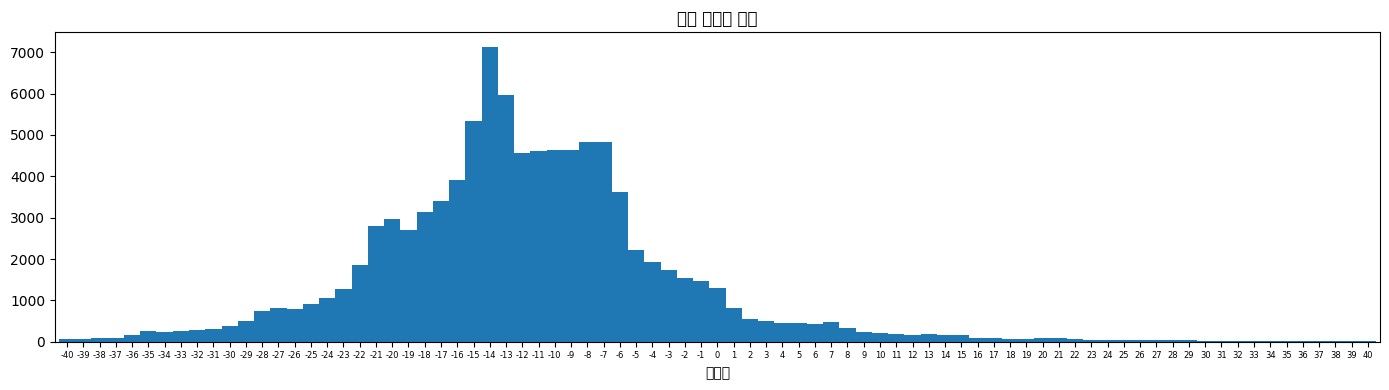

In [25]:
#변수 dist(=distribution)에 쿼리 할당
dist = q("""
SELECT
delay_days AS 지연일,
count(*) AS 건수
FROM order_fact
WHERE delay_days BETWEEN -40 AND 40
GROUP BY 1
ORDER BY 1
""")

#막대 그래프 그리기
dist.plot(x="지연일", y="건수", kind="bar", figsize=(14, 4), legend=False, width=1.0)
plt.title("배송 지연일 분포");         #그래프 제목
plt.xticks(rotation=0, fontsize=6);
plt.tight_layout();
plt.show()

**판단할 것**: 위 분포를 보고 현재 구간(−8 / −1 / 0 / 7 / 20)이 타당한가요?바꿀 거라면 sql/base.sql 의 delay_bucket 을 고치고, 왜 그렇게 나눴는지 docs/METRICS.md 에 적으세요.

[답안]

- 4분위로 구분(p25 -17일 / 중앙값 -12일 / p.75 -7일 ...)
- 정시(=0) 구분

- 지연 구분 but p.95가 3일 지연이라 일주일치 이상 자르는 것 의미 없다고 판단 => '1~7일 지연'과 '7일 지연' 두 파트(?)로만 자르기

CASE
WHEN o.order_delivered_customer_date IS NULL THEN '미상' WHEN date_diff('day', CAST(o.order_estimated_delivery_date AS TIMESTAMP), CAST(o.order_delivered_customer_date AS TIMESTAMP)) <= -17 THEN '①[1분위] 17일 조기'

WHEN date_diff('day', CAST(o.order_estimated_delivery_date AS TIMESTAMP), CAST(o.order_delivered_customer_date AS TIMESTAMP)) <= -12 THEN '②[2분위] 12일 조기'

WHEN date_diff('day', CAST(o.order_estimated_delivery_date AS TIMESTAMP), CAST(o.order_delivered_customer_date AS TIMESTAMP)) <= -7 THEN '③[3분위] 7일 조기'

WHEN date_diff('day', CAST(o.order_estimated_delivery_date AS TIMESTAMP), CAST(o.order_delivered_customer_date AS TIMESTAMP)) = 0 THEN '④ 정시'

WHEN date_diff('day', CAST(o.order_estimated_delivery_date AS TIMESTAMP), CAST(o.order_delivered_customer_date AS TIMESTAMP)) <= 7 THEN '⑤ 1~7일 지연'

ELSE '⑥ 7일+ 지연' END AS delay_bucket,

(2) 구간별 리뷰 점수 — 이 프로젝트의 핵심 표

*평균과 1점 비율을 따로 보는 이유=평균 점수는 완만하게 움직이는데 1점 비율은 급격히 튀는 구간이 있습니다. 평균만 보면 그 지점을 놓칩니다. 운영에서 문제가 되는 건 평균이 아니라 1점을 주고 떠나는 고객 입니다.

In [26]:
delay = q("""
SELECT delay_bucket AS 지연구간,
count(*) AS 주문수,
round(avg(review_score), 3) AS 평균점수,
round(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율,
round(100.0 * count(*) FILTER (WHERE review_score >= 4) / count(*), 1) AS 만족비율
FROM order_fact
WHERE delay_days IS NOT NULL AND has_review
GROUP BY 지연구간
ORDER BY 지연구간
""")
delay


,지연구간,주문수,평균점수,최저점비율,만족비율
0,①[1분위] 17일 조기,25570,4.316,6.8,83.4
1,②[2분위] 12일 조기,26748,4.332,6.2,84.0
2,③[3분위] 7일 조기,23431,4.287,6.5,82.8
3,④ 정시,1280,4.034,8.5,73.7
4,⑤ 1~7일 지연,16019,3.850,14.9,69.8
5,⑥ 7일+ 지연,2782,1.696,69.8,11.7


/tmp/ipykernel_1580/3550498175.py:15: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/3550498175.py:15: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/3550498175.py:15: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/3550498175.py:15: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/3550498175.py:15: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/3550498175.py:15: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_1580/3550498175.py:15: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tigh

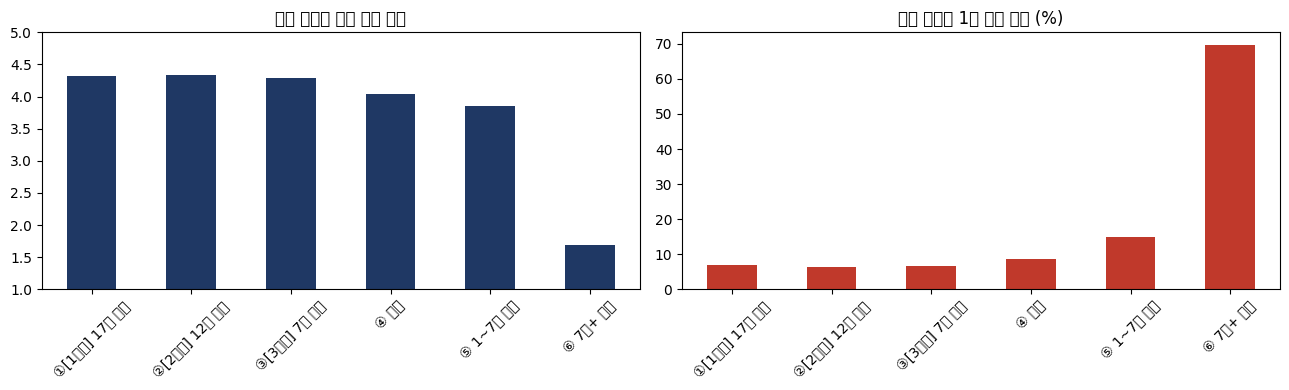

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

delay.plot(x="지연구간", y="평균점수",  kind="bar", ax=ax[0], legend=False, color="#1F3864")
ax[0].set_title("지연 구간별 평균 리뷰 점수");
ax[0].set_ylim(1, 5);
ax[0].set_xlabel("")

delay.plot(x="지연구간", y="최저점비율", kind="bar", ax=ax[1], legend=False, color="#C0392B")
ax[1].set_title("지연 구간별 1점 리뷰 비율 (%)");
ax[1].set_xlabel("")

for a in ax:
  a.tick_params(axis="x", rotation=45)

plt.tight_layout();
plt.show()


(3) **【직접 작성】 다른 요인을 고정해도 같은 패턴인가**

지금까지 본 건 상관관계 입니다. 늦게 오는 주문은 부피가 크거나 원거리이거나 특정 셀러에 몰려 있을 수 있고,그 요인이 점수를 깎았을 수도 있습니다.

할 일: 조건을 하나 고정하고도 같은 패턴이 남는지 확인하세요.

예를 들어- 카테고리 하나만 골라서 (WHERE category = '...')- 같은 주(state) 안에서만 (WHERE customer_state = 'SP')- 주문 금액대를 비슷하게 맞춰서 패턴이 남으면 결론이 단단해지고, 사라지면 그 사실 자체가 중요한 발견입니다.

In [28]:
#1_특정 셀러 문제인지 확인

#평점 낮은 셀러 구하기 (단, 주문수 100개 이상)
delay_seller_ranking = q("""
SELECT seller_id AS 셀러ID,
       count(*) AS 주문수,
       round(avg(delay_days), 3) AS 평균지연일,
       round(avg(review_score), 3) AS 평균점수,
       round(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율
FROM order_fact
WHERE delay_days > 0 AND has_review
GROUP BY 셀러ID
HAVING count(*) >= 100
ORDER BY 주문수 DESC, 최저점비율 DESC
""")

delay_seller_ranking

#분석1//악성 셀러(?) 있지만 주문수 미미 => 결론=특정 셀러 문제X
#분석2//7일+지연이지만 평균점수가 전체 평균(1.696)보다 낮음

,셀러ID,주문수,평균지연일,평균점수,최저점비율
0,4a3ca9315b744ce9f8e9374361493884,168,11.286,2.238,49.4
1,1f50f920176fa81dab994f9023523100,121,10.190,2.273,53.7
2,4869f7a5dfa277a7dca6462dcf3b52b2,116,9.207,2.052,56.0


In [29]:
#2_지역 배송 문제인지 확인

customer_state_check = q("""
  SELECT customer_state AS 배송지,
         count(*) AS 주문수,
         round(avg(review_score), 3) AS 평균점수,
         round(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율,
         round(100.0 * count(*) FILTER (WHERE review_score >= 4) / count(*), 1) AS 만족비율
  FROM order_fact
  WHERE delay_days IS NOT NULL AND has_review
  GROUP BY 배송지
  HAVING count(*) >= 1000
  ORDER BY 주문수 DESC, 최저점비율 DESC
""")

customer_state_check

#분석1//리우데자네이루(RJ), 상파울루(SP) 다음으로 주문수 많은데 최저점 비율은 SP의 약 2배 => Q. 원거리/지리적/구조적 문제 여부 어떻게 확인?


,배송지,주문수,평균점수,최저점비율,만족비율
0,SP,40267,4.246,7.9,81.4
1,RJ,12214,3.965,14.8,73.4
2,MG,11286,4.192,8.9,79.9
3,RS,5326,4.185,9.0,79.8
4,PR,4900,4.240,7.9,81.6
5,SC,3520,4.133,9.9,78.1
6,BA,3229,3.930,13.2,72.9
7,DF,2070,4.131,10.3,78.8
8,ES,1969,4.079,11.0,77.1
9,GO,1946,4.104,9.9,77.3


In [30]:
#3_품목 문제인지 확인(단, 주문수 100개 이상)

category_check = q("""
  SELECT category AS 품목,
         count(*) AS 주문수,
         round(avg(review_score), 3) AS 평균점수,
         round(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율,
         round(100.0 * count(*) FILTER (WHERE review_score >= 4) / count(*), 1) AS 만족비율
  FROM order_fact
  WHERE delay_days IS NOT NULL AND has_review
  GROUP BY 품목
  HAVING count(*) >= 100
  ORDER BY 최저점비율 DESC
""")

category_check


#부피 큰/무거운 품목만 모아 계산

delay_category = q("""
  SELECT
    CASE
    WHEN category IN ('office_furniture','bed_bath_table', 'furniture_living_room', 'kitchen_dining_laundry_garden_furniture'  ) THEN '가구'
    WHEN category IN ('audio', 'air_conditioning', 'computers', 'construction_tools_construction', 'electronics', 'home_construction', 'auto', 'garden_tools', 'home_appliances', 'costruction_tools_garden', 'home_appliances_2' ) THEN '가전'
    ELSE '기타'
    END AS 품목세분류,
    COUNT(*) AS 주문수,
    ROUND(avg(review_score), 3) AS 평균점수,
    ROUND(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율,
    ROUND(100.0 * count(*) FILTER (WHERE review_score >= 4) / count(*), 1) AS 만족비율
  FROM order_fact
  WHERE delay_days IS NOT NULL AND has_review
  GROUP BY 1
  ORDER BY 최저점비율 DESC

""")

delay_category

#분석//개선 우선순위 따진다면 '(대형)가구' 배송 먼저 개선해야


,품목세분류,주문수,평균점수,최저점비율,만족비율
0,가구,10970,3.971,12.3,73.2
1,가전,12739,4.154,9.7,79.4
2,기타,72121,4.184,9.4,79.7


In [31]:
#4_특정 시즌의 문제인지 확인(11월 블랙프라이데이, 12월 크리스마스 등)

season_check = q("""
  SELECT MONTH(purchase_month) AS 구매연월,
         count(*) AS 주문수,
         round(avg(review_score), 3) AS 평균점수,
         round(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율,
         round(100.0 * count(*) FILTER (WHERE review_score >= 4) / count(*), 1) AS 만족비율,
  FROM order_fact
  WHERE delay_days IS NOT NULL
    AND has_review
  GROUP BY 구매연월
  ORDER BY 최저점비율 DESC
""")

season_check


##분석/ 카니발 시즌(2~3월) 최저점 비율은 8월(아마 평수기?) 대비 2배 증가


,구매연월,주문수,평균점수,최저점비율,만족비율
0,3,9475,3.912,15.1,72.3
1,2,8151,3.946,14.0,72.8
2,11,7237,3.988,13.1,74.1
3,12,5462,4.088,10.8,77.2
4,1,7754,4.117,10.2,77.3
5,10,4713,4.192,9.0,80.2
6,4,9042,4.189,8.8,80.1
7,5,10239,4.236,8.0,81.1
8,6,9183,4.279,7.4,82.4
9,9,4119,4.267,7.2,82.2


결론 작성
아래 형식으로 한 문장을 만들어 docs/FINDINGS.md 에 옮기세요.
숫자 없는 문장은 쓰지 않습니다.

> 배송 지연 [ ] 일을 넘기는 구간부터 1점 리뷰 비율이 정시 대비 [ ] 배([ ]% → [ ]%)로 증가한다.> 평균 점수는 [ ] 점에서 [ ] 점으로 하락한다.> 다만 이는 상관관계이며, [ 통제한 요인 / 통제하지 못한 요인 ] 이 남아 있다

# 3. 카테고리 셀러

어디부터 손대야 하는가02에서 "지연되면 점수가 떨어진다"를 확인했다면, 이제 어디서 가장 크게 떨어지는가 를 봅니다.

개선 우선순위를 정하는 것이 목적입니다.

이 노트북의 후반부가 SQL 실력이 가장 많이 드러나는 구간 입니다.

시간을 제일 많이 쓰세요.

In [ ]:
import duckdb, pandas as pd
import matplotlib, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)

# 한글 깨짐 방지
for _f in [
    "AppleGothic",
    "Malgun Gothic",
    "NanumGothic",
    "NanumBarunGothic",
    "Noto Sans CJK KR",
    "Noto Sans KR",
]:
    if _f in {f.name for f in matplotlib.font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = _f
        break

plt.rcParams["axes.unicode_minus"] = False

# DuckDB는 CSV를 그대로 읽습니다. 적재 과정이 따로 없습니다.
con = duckdb.connect()
con.execute(open("sql/base.sql", encoding="utf-8").read().format(data="data/raw"))

def q(sql):
    """SQL을 실행해 pandas DataFrame으로 돌려줍니다."""
    return con.sql(sql).df()

q("SELECT count(*) AS 주문수 FROM order_fact")

,주문수
0,99441


(1)카테고리별 지연 타격도

같은 지연이라도 상품군에 따라 고객 반응이 다릅니다.

FILTER (WHERE ...) 를 쓰면 한 번의 집계로 조건별 값을 나란히 뽑을 수 있습니다.

주의 — HAVING count(*) >= 200 의 200은 제가 임의로 정한 값입니다.기준을 바꾸면 순위가 바뀝니다. 100, 500으로도 돌려 보고 순위가 뒤집히는지 확인한 뒤,어떤 기준을 왜 택했는지 docs/METRICS.md 에 적으세요.

In [ ]:
cat = q("""
  SELECT category AS 카테고리,
  count(*) AS 주문수,
  round(avg(review_score) FILTER (WHERE NOT is_late), 3) AS 정시_평균점수,
  round(avg(review_score) FILTER (WHERE is_late), 3)     AS 지연_평균점수,
  round(avg(review_score) FILTER (WHERE NOT is_late)           - avg(review_score) FILTER (WHERE is_late), 3)     AS 하락폭
  FROM order_fact
  WHERE has_review AND is_late IS NOT NULL AND category <> 'unknown'
  GROUP BY 카테고리
  HAVING count(*) >=300 AND count(*) FILTER (WHERE is_late) >= 30
  ORDER BY 하락폭 DESC NULLS LAST
  """)
cat


##지연된 품목 중 최소 주문 품목=오디오(341건)
#주문수=1000 => 21개 (*하락폭 1위 '악기(주문수 602건)' 제외)
##주문수=500 => 24개 (*하락폭 2위 '오디오(주문수 341건)', 20위 '음식' 제외)

,카테고리,주문수,정시_평균점수,지연_평균점수,하락폭
0,musical_instruments,602,4.435,1.913,2.522
1,audio,341,4.130,1.725,2.405
2,toys,3758,4.378,2.129,2.248
3,baby,2739,4.298,2.073,2.225
4,sports_leisure,7449,4.379,2.167,2.212
5,fashion_bags_accessories,1804,4.360,2.190,2.170
6,construction_tools_construction,719,4.306,2.173,2.133
7,stationery,2231,4.446,2.315,2.131
8,pet_shop,1674,4.381,2.253,2.128
9,perfumery,3061,4.405,2.290,2.115


/tmp/ipykernel_3555/933640794.py:10: UserWarning: Glyph 52852 (\N{HANGUL SYLLABLE KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_3555/933640794.py:10: UserWarning: Glyph 53580 (\N{HANGUL SYLLABLE TE}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_3555/933640794.py:10: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_3555/933640794.py:10: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_3555/933640794.py:10: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_3555/933640794.py:10: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_3555/933640794.py:10: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  plt.tight_layou

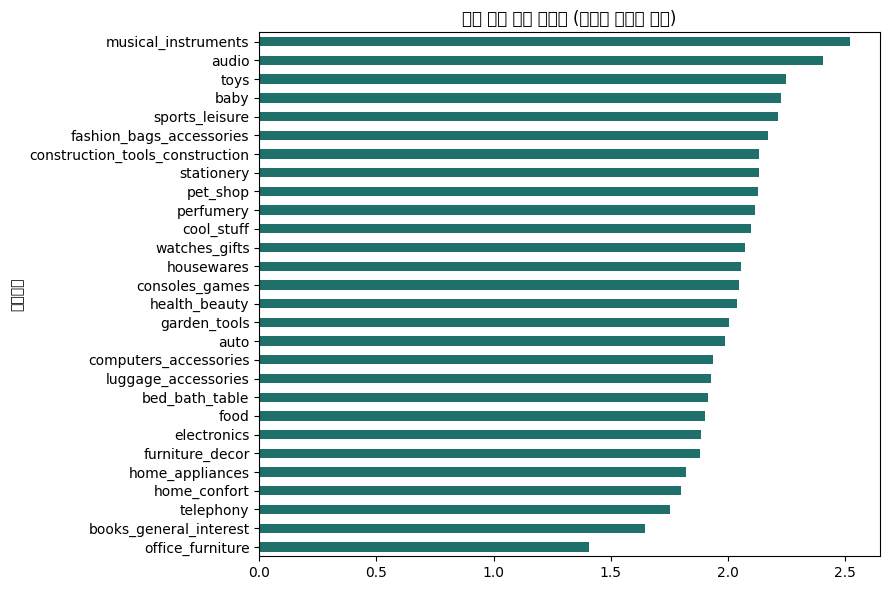

In [ ]:
cat.sort_values("하락폭").plot(
    x="카테고리",
    y="하락폭",
    kind="barh",
    figsize=(9, 6),
    legend=False,
    color="#1F6F6B",
  )
plt.title("정시 대비 점수 하락폭 (클수록 지연에 민감)");
plt.tight_layout();
plt.show()


In [ ]:
#기타① _지역별 지연

sta = q("""
  SELECT customer_state AS 배송지,
         count(*) AS 주문수,
         round(avg(review_score) FILTER (WHERE NOT is_late), 3) AS 정시_평균점수,
         round(avg(review_score) FILTER (WHERE is_late), 3)     AS 지연_평균점수,
         round(avg(review_score) FILTER (WHERE NOT is_late)           - avg(review_score) FILTER (WHERE is_late), 3)     AS 하락폭
  FROM order_fact
  WHERE has_review AND is_late IS NOT NULL AND category <> 'unknown'
  GROUP BY 배송지
  HAVING count(*) >= 1000 AND count(*) FILTER (WHERE is_late) >= 30
  ORDER BY 하락폭 DESC NULLS LAST
""")

sta

#리우데자네이루(RJ) 하락폭 최대 => Q. 원거리/지리적/구조적 문제 여부 어떻게 확인?

,배송지,주문수,정시_평균점수,지연_평균점수,하락폭
0,RJ,12035,4.245,1.915,2.330
1,DF,2040,4.259,1.975,2.285
2,PE,1562,4.301,2.027,2.273
3,CE,1259,4.250,2.036,2.215
4,RS,5248,4.313,2.217,2.096
5,GO,1898,4.236,2.176,2.059
6,MG,11121,4.276,2.362,1.914
7,SC,3464,4.290,2.378,1.912
8,BA,3188,4.147,2.347,1.800
9,SP,39718,4.327,2.554,1.773


In [ ]:
#기타②_특정 시즌(11월 블랙프라이데이, 12월 크리스마스 등)

sea = q("""
  SELECT MONTH(purchase_month) AS 구매연월,
         round(avg(review_score) FILTER (WHERE NOT is_late), 3) AS 정시_평균점수,
         round(avg(review_score) FILTER (WHERE is_late), 3)     AS 지연_평균점수,
         round(avg(review_score) FILTER (WHERE NOT is_late)           - avg(review_score) FILTER (WHERE is_late), 3)     AS 하락폭
  FROM order_fact
  WHERE has_review AND is_late IS NOT NULL AND category <> 'unknown'
  GROUP BY 구매연월
  HAVING count(*) FILTER (WHERE is_late) >= 30
  ORDER BY 하락폭 DESC NULLS LAST
""")

sea


##분석/ 카니발 시즌(2월) 하락폭 증가..


,구매연월,정시_평균점수,지연_평균점수,하락폭
0,2,4.213,1.925,2.288
1,1,4.242,2.038,2.204
2,12,4.256,2.113,2.144
3,3,4.228,2.097,2.131
4,11,4.241,2.179,2.062
5,4,4.284,2.314,1.971
6,6,4.315,2.389,1.926
7,7,4.349,2.580,1.768
8,9,4.346,2.594,1.751
9,10,4.256,2.544,1.712


(2) 【직접 작성】 셀러 성과 순위 — 윈도우 함수목표: "관리가 필요한 셀러"를 자동으로 뽑아내는 쿼리.순위만이 아니라 전체 대비 어디쯤인지 도 같이 보여야 판단 근거가 됩니다.

### 만들 컬럼
| 컬럼 | 쓸 함수 ||---|---|| 주문수, 평균점수, 지연율, 평균지연일 | 일반 집계 || 지연율 사분위 (1~4) | NTILE(4) OVER (ORDER BY 지연율) || 평균점수 순위 | RANK() OVER (ORDER BY 평균점수) || 전체 평균점수 (비교용으로 각 행에 붙이기) | avg(평균점수) OVER () |

### 윈도우 함수가 처음이라면
일반 집계(GROUP BY)는 여러 행을 **한 줄로 합칩니다.**윈도우 함수는 행을 그대로 두고 옆에 계산 결과를 한 칸 더 붙입니다.sqlavg(x) OVER ()                 -- 전체 평균을 모든 행에 붙임RANK() OVER (ORDER BY x DESC)  -- x 기준 순위를 붙임NTILE(4) OVER (ORDER BY x)     -- x 기준으로 4등분해 1~4 번호를 붙임

### 구조 힌트
집계를 먼저 하고, 그 결과에 윈도우 함수를 얹어야 하므로 CTE 두 단계로 나눕니다.

sql
WITH s AS (    
  SELECT seller_id,           
  count(*) AS 주문수,           
  round(avg(review_score), 3) AS 평균점수,           
  round(100.0 * count(*) FILTER (WHERE is_late)                 / count(*) FILTER (WHERE is_late IS NOT NULL), 1) AS 지연율    
  FROM order_fact    
  WHERE has_review AND is_late IS NOT NULL   
  GROUP BY seller_id    
  HAVING count(*) >= 30        -- ← 기준을 정하고 근거를 남길 것)SELECT *,       ...  -- 여기에 NTILE / RANK / avg(...) OVER () 추가
  FROM s
  ORDER BY 지연율 DESC

### 함께 기록할 한계
order_fact 의 seller_id 는 주문 내 최고가 상품의 셀러 입니다 (sql/base.sql 참고).
여러 셀러가 섞인 주문의 책임을 한 명에게 몰아주고 있다는 뜻이니, 결론에 이 한계를 함께 적으세요.

In [ ]:
#관리가 필요한 셀러=①지연율 높음 or ②최저점(=1) 리뷰 건수 많음

seller_rank = q("""
WITH s AS (
  SELECT seller_id AS 셀러ID,
         count(*) AS 주문수,
         count(*) FILTER (WHERE  is_late) AS 지연주문수,
         round(100.0 * count(*) FILTER (WHERE is_late) / count(*) FILTER (WHERE is_late IS NOT NULL), 1) AS 지연율,
         count(*) FILTER (WHERE review_score = 1) AS 최저점리뷰수,
         round(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율,
         round(avg(review_score), 3) AS 평균점수,
  FROM order_fact
  WHERE has_review AND is_late IS NOT NULL
  GROUP BY 셀러ID
  HAVING count(*) >= 30
)
SELECT *,
       NTILE(4) OVER (ORDER BY 지연율) AS 지연율_사분위,
       RANK() OVER (ORDER BY 평균점수) AS 평균점수_순위,
       round(avg(평균점수) OVER (), 3) AS 전체_평균점수
FROM s
ORDER BY 지연율 DESC
""")

seller_rank

,셀러ID,주문수,지연주문수,지연율,최저점리뷰수,최저점비율,평균점수,지연율_사분위,평균점수_순위,전체_평균점수
0,ad781527c93d00d89a11eecd9dcad7c1,36,12,33.3,10,27.8,3.278,4,9,4.173
1,ede0c03645598cdfc63ca8237acbe73d,42,13,31.0,10,23.8,3.571,4,25,4.173
2,54965bbe3e4f07ae045b90b0b8541f52,69,20,29.0,25,36.2,3.145,4,5,4.173
3,2a1348e9addc1af5aaa619b1a3679d6b,44,12,27.3,14,31.8,3.273,4,8,4.173
4,835f0f7810c76831d6c7d24c7a646d4d,41,11,26.8,11,26.8,3.415,4,17,4.173
...,...,...,...,...,...,...,...,...,...,...
614,718539d38d07dd351c76db862760e2e2,35,0,0.0,0,0.0,4.629,1,602,4.173
615,31561f325664a8a7aba4c8d0c3a9b3db,36,0,0.0,0,0.0,4.639,1,604,4.173
616,d566c37fa119d5e66c4e9052e83ee4ea,63,0,0.0,2,3.2,4.683,1,609,4.173
617,b410bdd36d5db7a65dcd42b7ead933b8,42,0,0.0,0,0.0,4.810,1,616,4.173


In [ ]:
#관리가 필요한 셀러 정의=①지연율 4분위 or ②최저점(=1) 비율 평균보다 높음  (**이유/지연율 4분위 AND (최저점 비율 > 전체 평균 최저점 비율) 셀러 36명)

management_seller = q("""
WITH s AS (
  SELECT seller_id AS 셀러ID,
         COUNT(*) AS 주문수,
         round(100.0 * count(*) FILTER (WHERE is_late) / count(*) FILTER (WHERE is_late IS NOT NULL), 1) AS 지연율,
         count(*) FILTER (WHERE review_score = 1) AS 최저점리뷰수,
         round(100.0 * count(*) FILTER (WHERE review_score = 1) / count(*), 1) AS 최저점비율,
         round(avg(review_score), 3) AS 평균점수
FROM order_fact
WHERE has_review AND is_late IS NOT NULL
GROUP BY 셀러ID
HAVING count(*) >= 30
),

s2 AS (
  SELECT *,
    NTILE(4) OVER (ORDER BY 지연율) AS 지연율_사분위,
    ROUND(AVG(최저점비율) OVER (), 1) AS 전체평균_최저점비율
  FROM s
)
SELECT *
FROM s2
WHERE (지연율_사분위 = 4) OR (최저점비율 > 전체평균_최저점비율)
ORDER BY 지연율 DESC, 최저점비율 DESC
""")

management_seller

,셀러ID,주문수,지연율,최저점리뷰수,최저점비율,평균점수,지연율_사분위,전체평균_최저점비율
0,ad781527c93d00d89a11eecd9dcad7c1,36,33.3,10,27.8,3.278,4,9.5
1,ede0c03645598cdfc63ca8237acbe73d,42,31.0,10,23.8,3.571,4,9.5
2,54965bbe3e4f07ae045b90b0b8541f52,69,29.0,25,36.2,3.145,4,9.5
3,2a1348e9addc1af5aaa619b1a3679d6b,44,27.3,14,31.8,3.273,4,9.5
4,835f0f7810c76831d6c7d24c7a646d4d,41,26.8,11,26.8,3.415,4,9.5
...,...,...,...,...,...,...,...,...
299,751bdc4d83a466c7206cd42e8f426b03,47,0.0,6,12.8,4.021,1,9.5
300,b1a81260566c1bac3114a6d124413f27,51,0.0,6,11.8,4.275,1,9.5
301,06e5eefc71ec47ae763c5c6f8db7064f,88,0.0,9,10.2,3.977,1,9.5
302,ed4acab38528488b65a9a9c603ff024a,31,0.0,3,9.7,3.806,1,9.5


(3) 대시보드에 붙이기

위 쿼리가 완성되면 app.py 의 "추가할 자리" 주석 아래에 아래처럼 한 번만 부르면 화면에 붙습니다.pythonblock(    "셀러 성과 순위",    """<완성한 SQL 그대로>""",    definition="- **지연율 사분위**: 전체 셀러를 지연율 기준 4등분 ...",    caveat="주문 30건 미만 셀러는 제외했습니다. 대표 셀러는 주문 내 최고가 상품 기준입니다.",)

결론 작성
> 셀러 [620] 곳 중 지연율 하위 사분위 [ 154 ] 곳이 전체 지연 주문의 [26.9 ] %를 차지한다.
> 이 [154] 곳만 관리해도 지연 주문의 [ 26.9] %가 개선 대상에 들어온다.
카테고리는:> [ musical_instruments ] 카테고리가 지연에 가장 민감해 정시 대비 [2.522 ] 점 하락하고, [ office_furniture ] 는 [2.354] 점으로 가장 둔감하다.

In [ ]:
#하위 사분위의 점유율 계산

con_1 = q("""
WITH s AS (
  SELECT seller_id AS 셀러ID,
         count(*) AS 주문수,
         count(*) FILTER (WHERE is_late) AS 지연주문수,
         round(100.0 * count(*) FILTER (WHERE is_late) / count(*) FILTER (WHERE is_late IS NOT NULL), 1) AS 지연율
  FROM order_fact
  WHERE has_review AND is_late IS NOT NULL
  GROUP BY seller_id
  HAVING count(*) >= 30
),
s2 AS (
  SELECT *,
         NTILE(4) OVER (ORDER BY 지연율 DESC) AS 지연율_사분위
  FROM s
)
SELECT
  ROUND(100.0 * COUNT(*) FILTER (WHERE 지연율_사분위 = 4) / COUNT(*) FILTER(WHERE 지연주문수), 1) AS 점유율
FROM s2
""")

con_1

,점유율
0,26.9


# 4.재구매

답이 안 나올 수도 있는 질문> 낮은 리뷰 점수가 재구매 감소로 이어지는가?

## 시작 전에 각오할 것이 데이터는 반복 구매 비중이 매우 낮습니다.

그래서 이 질문은 **"표본이 부족해 판단할 수 없다"가 결론일 가능성이 높습니다.**
그때 숫자를 억지로 만들지 마세요.표본 수와 함께 "이 데이터로는 답할 수 없다"를 근거 있게 적는 것이 정답이고,
**그렇게 쓸 줄 아는지가 이 프로젝트에서 가장 크게 평가받는 지점입니다.**
대부분의 포트폴리오는 잘 나온 결과만 싣습니다. 한계를 근거와 함께 적은 문서는 드물고,현업에서는 그쪽이 더 신뢰를 받습니다.

In [11]:
import duckdb, pandas as pd
import matplotlib, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)

# 한글 깨짐 방지
for _f in [
    "AppleGothic",
    "Malgun Gothic",
    "NanumGothic",
    "NanumBarunGothic",
    "Noto Sans CJK KR",
    "Noto Sans KR",
]:
    if _f in {f.name for f in matplotlib.font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = _f
        break

plt.rcParams["axes.unicode_minus"] = False

# DuckDB는 CSV를 그대로 읽습니다. 적재 과정이 따로 없습니다.
con = duckdb.connect()
con.execute(open("sql/base.sql", encoding="utf-8").read().format(data="data/raw"))

def q(sql):
    """SQL을 실행해 pandas DataFrame으로 돌려줍니다."""
    return con.sql(sql).df()

q("SELECT count(*) AS 주문수 FROM order_fact")

,주문수
0,99441


(1)먼저 표본이 있는지부터 확인분석을 설계하기 전에 애초에 답할 수 있는 질문인지 를 봅니다.

여기서 나온 숫자가 이 노트북의 결론을 사실상 결정합니다.

In [12]:
q("""
WITH per_person AS (
    SELECT
        customer_unique_id,
        count(*) AS n
    FROM order_fact
    WHERE customer_unique_id IS NOT NULL
    GROUP BY 1
)
SELECT
    count(*) AS 고객수,
    count(*) FILTER (WHERE n >= 2) AS 재구매고객수,
    round(100.0 * count(*) FILTER (WHERE n >= 2) / count(*), 2) AS 재구매율_퍼센트,
    max(n) AS 최다주문수
FROM per_person

""")

,고객수,재구매고객수,재구매율_퍼센트,최다주문수
0,96096,2997,3.12,17


(2)【직접 작성】 LEAD로 다음 주문 붙이기

LEAD() 는 같은 그룹 안에서 다음 행의 값 을 현재 행에 붙여 줍니다.

고객별로 주문을 시간순 정렬한 뒤 "다음 주문이 있는가"를 판정하는 데 씁니다.

sql

LEAD(purchased_at) OVER (PARTITION BY --- customer_unique_id ORDER BY purchased_at)- PARTITION BY = 고객 단위로 끊어서- ORDER BY = 그 안에서 시간순으로- 다음 주문이 없으면 NULL 이 들어옵니다 → 그게 "재구매 안 함"### 만들 것

1. 고객별 주문에 다음주문시점 을 붙인다

2. 각 고객의 첫 주문 만 남긴다 (ROW_NUMBER() ... = 1)

3. 첫 주문의 리뷰 점수별로 재구매 비율을 집계한다

4. 각 점수 구간의 표본 수를 반드시 함께 출력한다 ← 이게 결론의 근거가 됩니다

In [20]:
re = q("""
WITH ordered AS (
    -- [1번] 고객의 다음주문시점(LEAD) 확인 및 구매순서(ROW_NUMBER)
    SELECT
        customer_unique_id,
        review_score,
        purchased_at,
        LEAD(purchased_at) OVER (PARTITION BY customer_unique_id ORDER BY purchased_at) AS 다음구매,
        ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchased_at) AS 구매순서
    FROM order_fact
),
first_order AS (
    -- [2번] 각 고객의 '첫 주문'만 출력 & 재구매 여부(0 또는 1) 확인
    SELECT
        customer_unique_id,
        review_score,
        CASE WHEN 다음구매 IS NOT NULL THEN 1 ELSE 0 END AS 재구매
    FROM ordered
    WHERE 구매순서 = 1
)
  -- [3번 & 4번] 첫 주문의 리뷰 점수별 재구매 비율 & 각 점수 구간의 표본 수 출력
  SELECT
    review_score AS 첫주문리뷰점수,
    count(*) FILTER (WHERE 재구매 = 1) AS 재구매수,
    round(100.0 * count(*) FILTER (WHERE 재구매 = 1) / count(*), 1) AS 재구매율
  FROM first_order
  WHERE review_score IS NOT NULL
  GROUP BY 1
  ORDER BY 1
""")

re

,첫주문리뷰점수,재구매수,재구매율
0,1,350,3.2
1,2,88,2.9
2,3,242,3.1
3,4,524,2.8
4,5,1765,3.2


3. 결론 쓰기

— 두 갈래

###(A) 표본이 충분했다면> 첫 주문에 [ ] 점을 준 고객의 재구매율은 [ ] %(n=[ ]),> [ ] 점을 준 고객은 [ ] %(n=[ ])로 [ ] %p 차이가 있다.

### (B) 표본이 부족했다면 — 이렇게 쓰세요> 재구매 고객은 전체 [96096] 명 중 [2997 ] 명([3.12]%)에 그쳤다.


> 이를 리뷰 점수 5단계로 나누면 구간당 [ ] 명 수준이어서,> 점수별 재구매율 차이를 유의미하게 말할 수 없다.> 따라서 이 데이터로는 "낮은 점수가 이탈로 이어지는가"에 답할 수 없다고 판단하고 결론을 보류한다.> 이 질문에 답하려면 동일 고객의 장기 구매 이력이 필요하다.

(B)를 쓰는 걸 실패로 생각하지 마세요.답이 안 나온다는 것을 근거와 함께 밝히는 것도 분석 결과입니다.docs/FINDINGS.md 의 "확인하지 못한 것" 섹션이 그걸 위해 만들어져 있습니다.